# Coding Assignment: Did the New Checkout Page Work?
**Data Science: Foundations to Applications (SCD-4XX)** · Weeks 6–7 · Statistics I & II

**Total: 100 points** · Work individually · Estimated time: 2–3 hours

---
## The scenario
**ShopSphere**, an online retailer, redesigned its checkout page. For four weeks (1–28 Sept 2026), visitors were **randomly assigned** to the current page (`control`) or the redesign (`treatment`). You are the data scientist asked to advise leadership.

- The redesign cost **\$40,000** to build. Leadership will roll it out only if the **true conversion-rate lift is at least 1.0 percentage point (pp)**.
- The **primary metric** (declared before the test) is **conversion rate**. Time on page is a *secondary* metric.

## The data: `shopsphere_ab_test.csv` (keep it in the same folder as this notebook)
| Column | Meaning |
|---|---|
| `user_id` | Unique visitor ID |
| `visit_date` | Date of visit |
| `group` | `control` or `treatment` |
| `device` | `mobile`, `desktop` or `tablet` |
| `customer_type` | `new` or `returning` |
| `time_on_page_sec` | Seconds spent on the checkout page |
| `converted` | 1 if the visitor purchased, else 0 |
| `order_value` | Order value in dollars (only for converters; missing otherwise) |

## Rules & grading
- Write your code **in the empty code cells**, and your explanations **in the answer cells**. Use α = **0.05** throughout.
- Every task should work on its own (re-compute what you need from `df`), so the notebook runs **top to bottom**. Before submitting: `Kernel → Restart Kernel and Run All Cells`, and make sure there are no errors.
- Marks are given for correct code **and** correct interpretation. A p-value without a sentence explaining what it means earns at most half the points.
- Use `np.random.seed(2026)` once (in the setup cell) so your simulations are reproducible.
- **Submit** the executed `.ipynb` file (outputs visible).

| Part | Topic | Points |
|---|---|---|
| 1 | Descriptive statistics | 15 |
| 2 | Probability & distributions | 20 |
| 3 | CLT & confidence intervals | 15 |
| 4 | Hypothesis tests | 20 |
| 5 | Business recommendation | 20 |
| 6 | Statistical pitfalls | 10 |

## Part 0 · Setup & first look  *(ungraded, but required)*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

%matplotlib inline
sns.set_theme(style="whitegrid")
np.random.seed(2026)

df = pd.read_csv("shopsphere_ab_test.csv", parse_dates=["visit_date"])
print(df.shape)
df.head()

(10000, 8)


,user_id,visit_date,group,device,customer_type,time_on_page_sec,converted,order_value
0,1,2026-09-17,treatment,desktop,new,77.8,0,NaN
1,2,2026-09-16,control,mobile,new,52.4,0,NaN
2,3,2026-09-07,treatment,desktop,new,71.7,0,NaN
3,4,2026-09-07,treatment,mobile,new,29.8,0,NaN
4,5,2026-09-12,treatment,mobile,returning,46.4,0,NaN


In [2]:
# Explore: dtypes, missing values per column, number of users per group.
# Why does `order_value` have missing values? (You'll explain this in Task 1.3.)
print(df.dtypes, end="\n\n")
print("Missing values per column:")
print(df.isna().sum(), end="\n\n")
print("Users per group:")
print(df["group"].value_counts(), end="\n\n")
print("Date range:", df["visit_date"].min().date(), "to", df["visit_date"].max().date())
print("Duplicate user_ids:", df["user_id"].duplicated().sum())
print("Converted but order_value missing:", ((df["converted"] == 1) & df["order_value"].isna()).sum())
print("Not converted but order_value present:", ((df["converted"] == 0) & df["order_value"].notna()).sum())

user_id                      int64
visit_date          datetime64[us]
group                          str
device                         str
customer_type                  str
time_on_page_sec           float64
converted                    int64
order_value                float64
dtype: object

Missing values per column:
user_id                0
visit_date             0
group                  0
device                 0
customer_type          0
time_on_page_sec       0
converted              0
order_value         9038
dtype: int64

Users per group:
group
treatment    5000
control      5000
Name: count, dtype: int64

Date range: 2026-09-01 to 2026-09-28
Duplicate user_ids: 0
Converted but order_value missing: 0
Not converted but order_value present: 0


---
## Part 1 · Descriptive Statistics  *(15 pts)*

### Task 1.1 · Summary statistics  *(5 pts)*

For `order_value` (converters only), compute the **mean, median, standard deviation, variance, range and IQR**, and the **mode of `device`**. Put the first six in one tidy `pandas` Series called `summary`.

In [3]:
ov = df["order_value"].dropna()

q1, q3 = ov.quantile(0.25), ov.quantile(0.75)
summary = pd.Series({
    "mean": ov.mean(),
    "median": ov.median(),
    "std": ov.std(),
    "variance": ov.var(),
    "range": ov.max() - ov.min(),
    "IQR": q3 - q1,
}).round(2)
print(summary)
print("\nMode of device:", df["device"].mode()[0])

mean          49.59
median        38.13
std           45.57
variance    2076.96
range        683.08
IQR           40.04
dtype: float64

Mode of device: mobile


### Task 1.2 · Visualize & find outliers  *(5 pts)*

Draw a **histogram** (with vertical lines for mean and median) and a **boxplot** of `order_value` side by side. Use the **1.5 × IQR rule** to count how many orders are outliers.

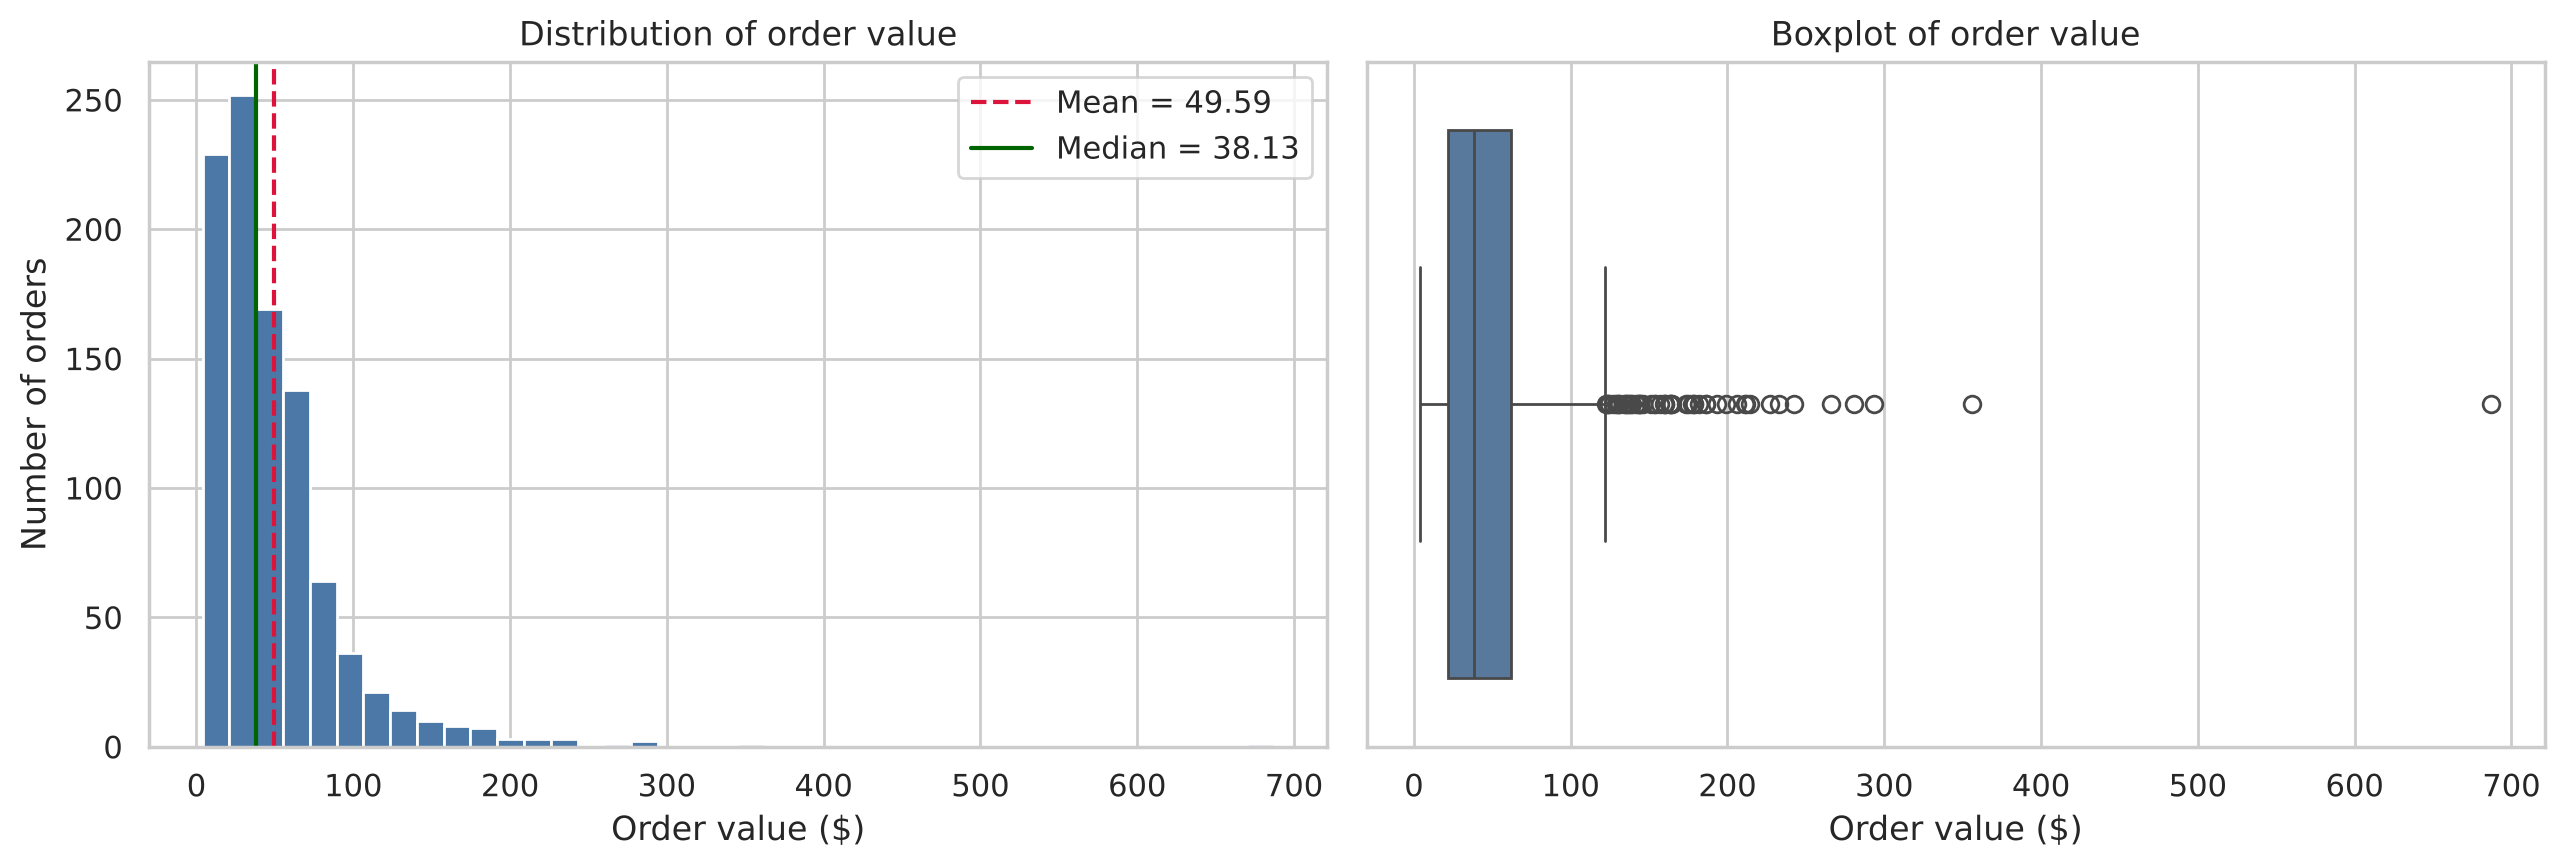

Outlier fences: [-38.28, 121.87]
Number of outliers: 55 of 962 orders (5.7%)
Largest order: $687.04


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(ov, bins=40, color="#4C78A8", edgecolor="white")
axes[0].axvline(ov.mean(), color="crimson", linestyle="--", label=f"Mean = {ov.mean():.2f}")
axes[0].axvline(ov.median(), color="darkgreen", linestyle="-", label=f"Median = {ov.median():.2f}")
axes[0].set_title("Distribution of order value")
axes[0].set_xlabel("Order value ($)")
axes[0].set_ylabel("Number of orders")
axes[0].legend()

sns.boxplot(x=ov, ax=axes[1], color="#4C78A8")
axes[1].set_title("Boxplot of order value")
axes[1].set_xlabel("Order value ($)")
plt.tight_layout()
plt.show()

q1, q3 = ov.quantile(0.25), ov.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = ov[(ov < lower) | (ov > upper)]
print(f"Outlier fences: [{lower:.2f}, {upper:.2f}]")
print(f"Number of outliers: {len(outliers)} of {len(ov)} orders ({len(outliers)/len(ov):.1%})")
print(f"Largest order: ${ov.max():.2f}")

**Interpretation (Task 1.2):** The histogram is a right-skewed distribution with the mean to the right of the median, and the boxplot shows a dense box with many points beyond the upper whisker; the 1.5 × IQR rule flags 55 outliers (5.7% of orders, all on the high side, above \$121.87).

### Task 1.3 · Interpret  *(5 pts)*

In 3–4 sentences: (a) Describe the **shape** of the distribution. (b) Which measure of centre and which measure of spread would you report to leadership, and why? (c) Why does `order_value` have missing values?

**Your answer:**

(a) Order value is strongly **right-skewed** (skewness ≈ 4.5): most orders fall between about \$20 and \$60, but a long tail of large orders stretches out to \$687, which pulls the mean (\$49.59) well above the median (\$38.13). 55 orders (5.7%) are outliers by the 1.5 × IQR rule (above \$121.87).
(b) I would report the **median (\$38.13)** as the typical order and the **IQR (\$40.04)** as the spread, because both are robust to the extreme orders, whereas the mean (\$49.59) and standard deviation (\$45.57) are inflated by the tail. (The mean is still the right number when the question is about total revenue.)
(c) `order_value` is missing for all 9,038 visitors who did **not** convert: a visitor who never bought has no order, so the value is *structurally* missing (not randomly lost data). All 962 converters have a value, so there is nothing to impute, and we must remember the averages describe buyers only.

---
## Part 2 · Probability & Distributions  *(20 pts)*

### Task 2.1 · Binomial  *(5 pts)*

Let `p_control` be the observed conversion rate in the **control** group. Suppose **200 new visitors** see the control page. Compute the probability that **at least 20** of them convert, (a) **exactly** with `scipy.stats.binom` and (b) by **simulation** with `np.random.binomial` (100,000 repetitions). Do they agree?

In [5]:
p_control = df.loc[df["group"] == "control", "converted"].mean()
n, k = 200, 20
print(f"Observed control conversion rate p_control = {p_control:.4f}  (expected conversions in 200 visitors: {n*p_control:.1f})")

# (a) exact: P(X >= 20) = 1 - P(X <= 19) = sf(19)
p_exact = stats.binom.sf(k - 1, n, p_control)

# (b) simulation
sims = np.random.binomial(n, p_control, size=100_000)
p_sim = (sims >= k).mean()

print(f"(a) Exact   P(X >= 20) = {p_exact:.4f}")
print(f"(b) Simulated P(X >= 20) = {p_sim:.4f}")
print(f"Absolute difference = {abs(p_exact - p_sim):.4f}")

Observed control conversion rate p_control = 0.0924  (expected conversions in 200 visitors: 18.5)
(a) Exact   P(X >= 20) = 0.3897
(b) Simulated P(X >= 20) = 0.3900
Absolute difference = 0.0003


**Interpretation (Task 2.1):** The exact binomial probability of at least 20 conversions among 200 visitors is **0.3897**, and the simulation gives **0.3900**; the two agree to within 0.0003, which is just simulation noise. With a 9.24% conversion rate we expect about 18.5 conversions in 200 visitors, so reaching 20 or more is quite ordinary (roughly a 39% chance).

### Task 2.2 · Poisson  *(5 pts)*

The support team receives on average **3.2 tickets per hour**. Compute (a) the probability of **no tickets** in an hour, (b) the probability of **more than 6 tickets** in an hour, (c) the **smallest staffing level `k`** such that the chance of *more than k* tickets in an hour is **at most 1%** (hint: `isf`). Check (b) with a simulation.

In [6]:
lam = 3.2

# (a) no tickets
p0 = stats.poisson.pmf(0, lam)
# (b) more than 6 tickets = P(X > 6) = sf(6)
p_gt6 = stats.poisson.sf(6, lam)
# (c) smallest k with P(X > k) <= 0.01
k_staff = int(stats.poisson.isf(0.01, lam))

print(f"(a) P(no tickets in an hour)      = {p0:.4f}")
print(f"(b) P(more than 6 tickets)        = {p_gt6:.4f}")
print(f"(c) Smallest k with P(X > k) <= 1% : k = {k_staff}  "
      f"(P(X > {k_staff}) = {stats.poisson.sf(k_staff, lam):.4f}; "
      f"P(X > {k_staff-1}) = {stats.poisson.sf(k_staff-1, lam):.4f})")

# Simulation check of (b)
sim = np.random.poisson(lam, size=100_000)
print(f"Simulated P(X > 6)                = {(sim > 6).mean():.4f}")

(a) P(no tickets in an hour)      = 0.0408
(b) P(more than 6 tickets)        = 0.0446
(c) Smallest k with P(X > k) <= 1% : k = 8  (P(X > 8) = 0.0057; P(X > 7) = 0.0168)
Simulated P(X > 6)                = 0.0440


**Interpretation (Task 2.2):** An hour with no tickets happens about 4.1% of the time and more than 6 tickets about 4.5% of the time (the simulation gives 4.4%, which agrees). Staffing for **k = 8** tickets per hour is the smallest level where the chance of being overwhelmed is at most 1% (P(X > 8) = 0.57%, whereas P(X > 7) = 1.68% is still above 1%).

### Task 2.3 · Conditional probability from data  *(5 pts)*

Using the full dataset, compute: `P(convert)`, `P(convert | returning)`, `P(convert | new)`, `P(mobile AND convert)`, and `P(convert | mobile)`. Then, in a comment or print statement, state whether **customer type and conversion look independent**.

In [7]:
p_conv = df["converted"].mean()
p_conv_ret = df.loc[df["customer_type"] == "returning", "converted"].mean()
p_conv_new = df.loc[df["customer_type"] == "new", "converted"].mean()
p_mobile_and_conv = ((df["device"] == "mobile") & (df["converted"] == 1)).mean()
p_conv_mobile = df.loc[df["device"] == "mobile", "converted"].mean()
p_mobile = (df["device"] == "mobile").mean()

print(f"P(convert)                = {p_conv:.4f}")
print(f"P(convert | returning)    = {p_conv_ret:.4f}")
print(f"P(convert | new)          = {p_conv_new:.4f}")
print(f"P(mobile AND convert)     = {p_mobile_and_conv:.4f}")
print(f"P(convert | mobile)       = {p_conv_mobile:.4f}")
print(f"Check: P(mobile) x P(convert | mobile) = {p_mobile * p_conv_mobile:.4f}")

# Formal check of independence between customer type and conversion
ct = pd.crosstab(df["customer_type"], df["converted"])
chi2, p_val, _, _ = stats.chi2_contingency(ct)
print(f"\nChi-square test customer_type vs converted: chi2 = {chi2:.2f}, p = {p_val:.4g}")
if p_val < 0.05:
    print("=> NOT independent: returning and new customers convert at clearly different rates, "
          "so P(convert | returning) != P(convert).")
else:
    print("=> Consistent with independence: P(convert | returning) is about equal to P(convert).")

P(convert)                = 0.0962
P(convert | returning)    = 0.1432
P(convert | new)          = 0.0766
P(mobile AND convert)     = 0.0497
P(convert | mobile)       = 0.0894
Check: P(mobile) x P(convert | mobile) = 0.0497

Chi-square test customer_type vs converted: chi2 = 105.19, p = 1.108e-24
=> NOT independent: returning and new customers convert at clearly different rates, so P(convert | returning) != P(convert).


**Interpretation (Task 2.3):** Returning customers convert at 14.3% versus 7.7% for new customers, while the overall rate is 9.6%. Since P(convert | returning) ≠ P(convert), **customer type and conversion are not independent** (chi-square p ≈ 10⁻²⁴): returning customers are much more likely to buy. By contrast, P(convert | mobile) = 8.9% is close to the overall 9.6%.

### Task 2.4 · Bayes' theorem: fraud detection  *(5 pts)*

2% of orders are fraudulent. A fraud model flags **90%** of fraudulent orders but also flags **5%** of legitimate ones. Write a function `p_fraud_given_flag(prevalence, sensitivity, false_positive_rate)` and use it to find the probability that a **flagged** order is really fraud. Then recompute for a prevalence of **0.2%**.

In [8]:
def p_fraud_given_flag(prevalence, sensitivity, false_positive_rate):
    """P(fraud | flagged) by Bayes' theorem."""
    p_flag = sensitivity * prevalence + false_positive_rate * (1 - prevalence)  # total probability
    return sensitivity * prevalence / p_flag

for prev in (0.02, 0.002):
    post = p_fraud_given_flag(prev, 0.90, 0.05)
    print(f"Prevalence {prev:.1%}: P(fraud | flagged) = {post:.4f} ({post:.1%});  "
          f"P(legitimate | flagged) = {1 - post:.1%}")

Prevalence 2.0%: P(fraud | flagged) = 0.2687 (26.9%);  P(legitimate | flagged) = 73.1%
Prevalence 0.2%: P(fraud | flagged) = 0.0348 (3.5%);  P(legitimate | flagged) = 96.5%


### Task 2.4b · Interpret  *(0 pts)*

*(Included in the 5 points of Task 2.4.)* In 2 sentences: why is a flagged order still more likely to be legitimate than fraudulent, and what does this mean for how the company should use the flag?

**Your answer:** Fraud is rare, so the 5% false-alarm rate is applied to the 98% of orders that are legitimate (≈ 4.9% of all orders flagged by mistake), which is far more than the 90% × 2% = 1.8% of orders that are flagged correctly; hence only about **26.9%** of flagged orders are fraud, and just **3.5%** when prevalence is 0.2%. The flag should therefore be used as a trigger for a cheap second check (manual review or extra verification) rather than for automatically cancelling orders, otherwise the company would block mostly good customers.

---
## Part 3 · Central Limit Theorem & Confidence Intervals  *(15 pts)*

### Task 3.1 · CLT in action  *(5 pts)*

Treat the observed `order_value` values as a skewed population. For sample sizes **n = 5, 30 and 100**, draw **1,000 samples** (with `np.random.choice`), record each sample's mean, and plot the three histograms side by side. Print the **skewness** (`stats.skew`) and the **standard deviation of the sample means** for each `n`, next to the theoretical `σ/√n`.

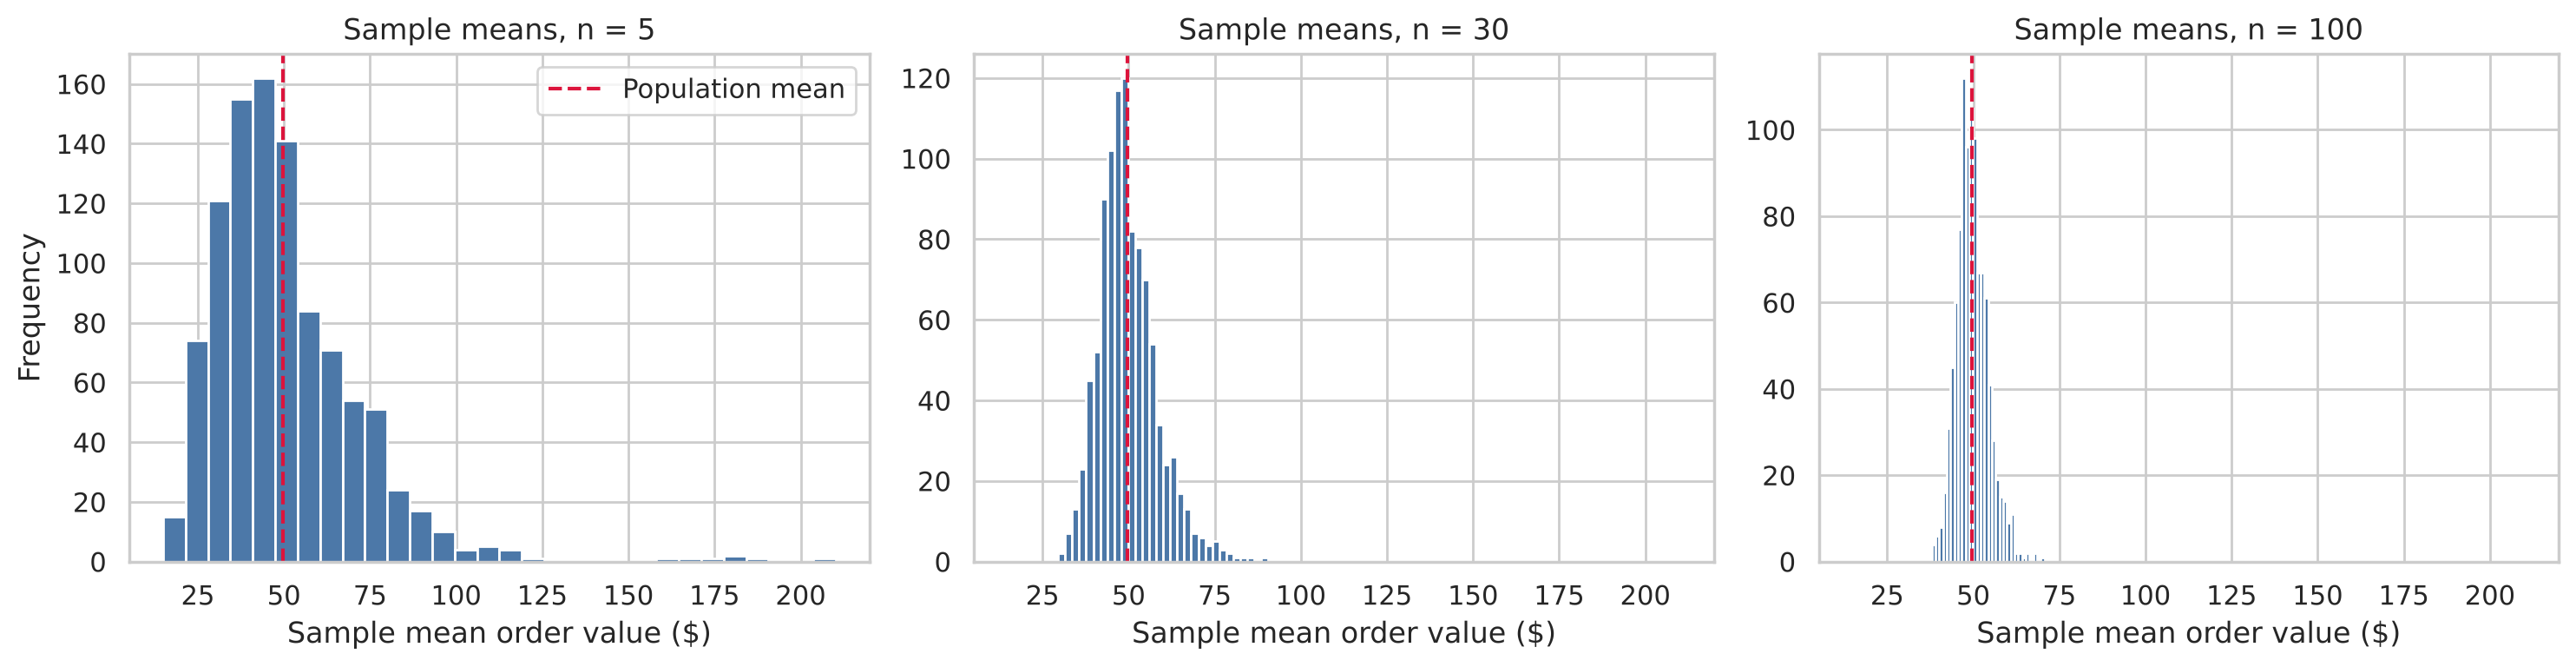

Skewness of the population: 4.52

   n |  skewness of means |  SD of sample means |  theoretical sigma/sqrt(n)
   5 |              2.140 |              21.183 |                     20.371
  30 |              0.870 |               8.471 |                      8.316
 100 |              0.597 |               4.630 |                      4.555


In [9]:
population = ov.values
sigma = population.std()   # population standard deviation (ddof = 0)
sizes = [5, 30, 100]
n_samples = 1000

sample_means = {}
for n in sizes:
    sample_means[n] = np.array([np.random.choice(population, size=n, replace=True).mean()
                                for _ in range(n_samples)])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, n in zip(axes, sizes):
    ax.hist(sample_means[n], bins=30, color="#4C78A8", edgecolor="white")
    ax.axvline(population.mean(), color="crimson", linestyle="--", label="Population mean")
    ax.set_title(f"Sample means, n = {n}")
    ax.set_xlabel("Sample mean order value ($)")
axes[0].set_ylabel("Frequency")
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"Skewness of the population: {stats.skew(population):.2f}\n")
print(f"{'n':>4} | {'skewness of means':>18} | {'SD of sample means':>19} | {'theoretical sigma/sqrt(n)':>26}")
for n in sizes:
    print(f"{n:>4} | {stats.skew(sample_means[n]):>18.3f} | {sample_means[n].std():>19.3f} | {sigma/np.sqrt(n):>26.3f}")

### Task 3.1b · Interpret  *(0 pts)*

*(Included in Task 3.1.)* In 2–3 sentences, explain what the plots show and why this matters for confidence intervals on **mean order value**.

**Your answer:** The population of order values is very skewed (skewness 4.5), but the distribution of *sample means* becomes steadily more symmetric and bell-shaped as n grows (skewness 2.14 at n = 5, 0.87 at n = 30, 0.60 at n = 100) and narrower, with a spread that matches the theoretical σ/√n (21.2 vs 20.4, 8.5 vs 8.3, 4.6 vs 4.6). This is the Central Limit Theorem, and it is why a t-based or normal-based confidence interval for **mean order value** is reasonable even though individual orders are skewed, provided n is large enough (here roughly 460–500 orders per group; n = 30 is still visibly skewed for data this extreme).

### Task 3.2 · CI for mean order value  *(5 pts)*

Compute a **95% t-based confidence interval** for the mean `order_value` separately for the control and treatment groups (converters only). Print the sample size, mean and interval for each.

In [10]:
for g in ["control", "treatment"]:
    x = df.loc[(df["group"] == g) & df["order_value"].notna(), "order_value"]
    n = len(x)
    m = x.mean()
    se = stats.sem(x)
    lo, hi = stats.t.interval(0.95, df=n - 1, loc=m, scale=se)
    print(f"{g:>9}: n = {n}, mean = ${m:.2f}, 95% CI = (${lo:.2f}, ${hi:.2f})")

  control: n = 462, mean = $49.51, 95% CI = ($45.75, $53.26)
treatment: n = 500, mean = $49.67, 95% CI = ($45.33, $54.01)


**Interpretation (Task 3.2):** Among converters, mean order value is \$49.51 in control (95% CI \$45.75 to \$53.26) and \$49.67 in treatment (95% CI \$45.33 to \$54.01). The intervals overlap almost completely, so there is no evidence that the redesign changed how much buyers spend.

### Task 3.3 · CI for the difference in conversion rates  *(5 pts)*

Write a function `diff_prop_ci(x1, n1, x2, n2, conf=0.95)` returning the CI for `p2 - p1` using the normal approximation `diff ± z × SE` with `SE = sqrt(p1(1-p1)/n1 + p2(1-p2)/n2)` (get `z` from `stats.norm.ppf`). Apply it to control (group 1) vs treatment (group 2) at **95%** and **99%**. What happens to the width, and why?

In [11]:
def diff_prop_ci(x1, n1, x2, n2, conf=0.95):
    """CI for p2 - p1 (normal approximation). Returns (diff, lower, upper)."""
    p1, p2 = x1 / n1, x2 / n2
    diff = p2 - p1
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    return diff, diff - z * se, diff + z * se


x_c, n_c = df.loc[df["group"] == "control", "converted"].sum(), (df["group"] == "control").sum()
x_t, n_t = df.loc[df["group"] == "treatment", "converted"].sum(), (df["group"] == "treatment").sum()
print(f"Control: {x_c}/{n_c} = {x_c/n_c:.4f};  Treatment: {x_t}/{n_t} = {x_t/n_t:.4f}\n")

for conf in (0.95, 0.99):
    d, lo, hi = diff_prop_ci(x_c, n_c, x_t, n_t, conf)
    print(f"{conf:.0%} CI for p_T - p_C: diff = {d*100:.2f} pp, "
          f"CI = ({lo*100:.2f} pp, {hi*100:.2f} pp), width = {(hi-lo)*100:.2f} pp")

Control: 462/5000 = 0.0924;  Treatment: 500/5000 = 0.1000

95% CI for p_T - p_C: diff = 0.76 pp, CI = (-0.40 pp, 1.92 pp), width = 2.31 pp
99% CI for p_T - p_C: diff = 0.76 pp, CI = (-0.76 pp, 2.28 pp), width = 3.04 pp


**Interpretation (Task 3.3):** The 95% CI for the lift is (−0.40 pp, +1.92 pp), width 2.31 pp; the 99% CI is (−0.76 pp, +2.28 pp), width 3.04 pp. The interval gets **wider** at higher confidence because the critical value z grows (1.96 → 2.58) while the standard error stays the same: to be more sure of capturing the true difference we must accept a less precise range. Both intervals contain 0.

---
## Part 4 · Hypothesis Testing  *(20 pts)*

### Task 4.1 · Hypotheses  *(3 pts)*

For the **primary metric**, write H₀ and H₁ in words *and* symbols (use `p_C` and `p_T` for the true conversion rates), say whether the test is one- or two-tailed, and justify it.

**Your answer:**

- **H₀ (no difference):** the new checkout page does not change the true conversion rate: **p_T = p_C** (p_T − p_C = 0).
- **H₁ (there is a difference):** the true conversion rates differ: **p_T ≠ p_C**.

The test is **two-tailed**. The redesign could in principle *lower* conversion (for example by confusing customers), and leadership would want to detect that as much as an improvement; a one-tailed test (p_T > p_C) would be blind to harm and was not pre-declared. (The business rule of "lift ≥ 1.0 pp" is a separate practical threshold that we judge with the confidence interval, not part of H₀.)

### Task 4.2 · Primary metric test  *(5 pts)*

Build the `group × converted` cross-tab and run the appropriate test. Report the test statistic, the p-value, and your decision. (Run it with the default continuity correction **and** with `correction=False`; do they lead to the same decision?)

In [12]:
ct = pd.crosstab(df["group"], df["converted"])
ct.columns = ["not converted", "converted"]
print(ct, end="\n\n")

for corr in (True, False):
    chi2, p, dof, expected = stats.chi2_contingency(ct, correction=corr)
    label = "with continuity correction" if corr else "without correction      "
    print(f"{label}: chi2 = {chi2:.3f}, dof = {dof}, p = {p:.4f} -> "
          f"{'reject H0' if p < 0.05 else 'fail to reject H0'} at alpha = 0.05")

# For reference: the equivalent two-proportion z-test (two-sided)
p_c, p_t = ct.loc["control", "converted"] / ct.loc["control"].sum(), ct.loc["treatment", "converted"] / ct.loc["treatment"].sum()
p_pool = ct["converted"].sum() / ct.values.sum()
se = np.sqrt(p_pool * (1 - p_pool) * (1 / ct.loc["control"].sum() + 1 / ct.loc["treatment"].sum()))
z = (p_t - p_c) / se
print(f"\nTwo-proportion z-test: z = {z:.3f}, two-sided p = {2*stats.norm.sf(abs(z)):.4f}  (z^2 = {z**2:.3f})")

           not converted  converted
group                              
control             4538        462
treatment           4500        500

with continuity correction: chi2 = 1.575, dof = 1, p = 0.2095 -> fail to reject H0 at alpha = 0.05
without correction      : chi2 = 1.661, dof = 1, p = 0.1975 -> fail to reject H0 at alpha = 0.05

Two-proportion z-test: z = 1.289, two-sided p = 0.1975  (z^2 = 1.661)


**Interpretation (Task 4.2):** A chi-square test of independence on the 2 × 2 table (equivalent to a two-sided two-proportion z-test) gives χ² = 1.575, p = 0.2095 with the continuity correction and χ² = 1.661, p = 0.1975 without. Both lead to the **same decision: fail to reject H₀** at α = 0.05. In words: if the two pages truly converted equally, a gap at least as large as 9.24% vs 10.00% would appear about 20% of the time by chance, so the data do not provide significant evidence of a difference (this is not proof that there is no difference).

### Task 4.3 · Secondary metric: time on page  *(4 pts)*

Run a **Welch t-test** (`equal_var=False`) on `time_on_page_sec`, control vs treatment. Also report the mean difference in seconds and **Cohen's d** (`d = mean difference / sqrt((s₁² + s₂²)/2)`). Is the result statistically significant? Is it practically significant? Explain in a markdown cell below your code.

In [13]:
t_c = df.loc[df["group"] == "control", "time_on_page_sec"]
t_t = df.loc[df["group"] == "treatment", "time_on_page_sec"]

t_stat, p_val = stats.ttest_ind(t_t, t_c, equal_var=False)
mean_diff = t_t.mean() - t_c.mean()
cohens_d = mean_diff / np.sqrt((t_c.var() + t_t.var()) / 2)

print(f"Control mean   = {t_c.mean():.2f} s (SD {t_c.std():.2f})")
print(f"Treatment mean = {t_t.mean():.2f} s (SD {t_t.std():.2f})")
print(f"Mean difference (treatment - control) = {mean_diff:.2f} s")
print(f"Welch t = {t_stat:.3f}, p = {p_val:.3g}")
print(f"Cohen's d = {cohens_d:.3f}")

Control mean   = 53.48 s (SD 19.04)
Treatment mean = 56.58 s (SD 18.60)
Mean difference (treatment - control) = 3.10 s
Welch t = 8.229, p = 2.12e-16
Cohen's d = 0.165


### Task 4.3b · Statistical vs practical significance  *(0 pts)*

*(Part of Task 4.3.)* Interpret the result above.

**Your answer:** Treatment visitors spent about **3.1 seconds longer** on the page (56.6 s vs 53.5 s), and the Welch t-test says this is **statistically significant** (t = 8.23, p ≈ 2 × 10⁻¹⁶), i.e. such a gap would essentially never arise by chance if the pages were equal. But Cohen's d is only **0.165**, below the conventional "small" benchmark of 0.2, and 3 seconds is about 6% of a 55-second visit, so it is **practically minor**: with 5,000 users per group even a tiny difference becomes significant. It is also not clear whether longer time on a checkout page is good (more engagement) or bad (more friction), and it is a secondary metric, so it cannot justify the rollout on its own.

### Task 4.4 · ANOVA across devices  *(5 pts)*

Test whether **mean time on page differs by device** (3 groups). Use the right test, then a **Tukey HSD** post-hoc test. Which pairs of devices differ? (Remember: groups from `df.groupby('device')` are ordered alphabetically: desktop, mobile, tablet.) Why not run three t-tests instead?

In [14]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

groups = {name: g["time_on_page_sec"].values for name, g in df.groupby("device")}  # desktop, mobile, tablet
print(df.groupby("device")["time_on_page_sec"].agg(["count", "mean", "std"]).round(2), end="\n\n")

f_stat, p_val = stats.f_oneway(*groups.values())
print(f"One-way ANOVA: F = {f_stat:.2f}, p = {p_val:.3g}\n")

tukey = pairwise_tukeyhsd(endog=df["time_on_page_sec"], groups=df["device"], alpha=0.05)
print(tukey)

         count   mean    std
device                      
desktop   3411  63.74  17.89
mobile    5560  49.41  17.48
tablet    1029  56.49  18.18

One-way ANOVA: F = 696.62, p = 5.9e-284



 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1 group2 meandiff p-adj  lower    upper   reject
------------------------------------------------------
desktop mobile -14.3243   0.0 -15.2264 -13.4222   True
desktop tablet  -7.2447   0.0  -8.7199  -5.7695   True
 mobile tablet   7.0796   0.0    5.672   8.4872   True
------------------------------------------------------


**Interpretation (Task 4.4):** A one-way ANOVA is the right test for comparing 3 means: F = 696.6, p ≈ 6 × 10⁻²⁸⁴, so mean time on page differs by device. Tukey HSD shows that **all three pairs differ** (all adjusted p < 0.001, none of the intervals includes 0): desktop (63.7 s) is longest, tablet (56.5 s) is in the middle, and mobile (49.4 s) is shortest; mobile is about 14.3 s shorter than desktop and about 7.1 s shorter than tablet. (statsmodels reports group2 − group1, so the desktop–mobile difference appears as −14.3.) Running three separate t-tests at α = 0.05 would inflate the overall (family-wise) false-positive risk to about 1 − 0.95³ ≈ 14%; ANOVA tests all groups with one test at 5%, and Tukey's procedure keeps the family-wise error at 5% for the pairwise comparisons.

### Task 4.5 · Did randomization work?  *(3 pts)*

A valid A/B test needs comparable groups. Run chi-square tests of **`group` vs `device`** and **`group` vs `customer_type`**. What result do you *hope* to see, and what do you conclude?

In [15]:
for other in ["device", "customer_type"]:
    ct = pd.crosstab(df["group"], df[other])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f"group vs {other}: chi2 = {chi2:.3f}, dof = {dof}, p = {p:.4f}")
    print((pd.crosstab(df["group"], df[other], normalize="index") * 100).round(1).to_string(), end="\n\n")

group vs device: chi2 = 2.348, dof = 2, p = 0.3091
device     desktop  mobile  tablet
group                             
control       33.5    56.4    10.1
treatment     34.7    54.8    10.4

group vs customer_type: chi2 = 1.405, dof = 1, p = 0.2359
customer_type   new  returning
group                         
control        70.1       29.9
treatment      71.2       28.8



**Interpretation (Task 4.5):** In a randomization check we *hope* **not** to find a significant association between group and these characteristics (a large p-value), because that means the groups are comparable. Group vs device gives p = 0.31 and group vs customer type gives p = 0.24, and the splits are almost identical in both groups (about 55–56% mobile and 29–30% returning). There is no evidence of imbalance, so randomization looks successful and any difference in outcomes can be attributed to the page rather than to a different visitor mix.

---
## Part 5 · From Statistics to a Business Recommendation  *(20 pts)*

### Task 5.1 · Effect size vs the business threshold  *(5 pts)*

Compute the **absolute lift** (in pp), the **relative lift** (%), and the **95% CI** for the lift (reuse your `diff_prop_ci` or recompute). Then answer in code: (i) does the CI exclude 0? (ii) does the CI **lower bound** reach the 1.0 pp business threshold? (iii) does the CI **upper bound** reach it?

In [16]:
THRESHOLD_PP = 1.0

diff, lo, hi = diff_prop_ci(x_c, n_c, x_t, n_t, 0.95)
p_c, p_t = x_c / n_c, x_t / n_t

abs_lift_pp = diff * 100
rel_lift_pct = (p_t - p_c) / p_c * 100
lo_pp, hi_pp = lo * 100, hi * 100

print(f"Control rate   = {p_c:.2%}")
print(f"Treatment rate = {p_t:.2%}")
print(f"Absolute lift  = {abs_lift_pp:.2f} pp")
print(f"Relative lift  = {rel_lift_pct:.1f} %")
print(f"95% CI for lift = ({lo_pp:.2f} pp, {hi_pp:.2f} pp)\n")

print(f"(i)   CI excludes 0?                         {lo_pp > 0 or hi_pp < 0}")
print(f"(ii)  CI lower bound >= {THRESHOLD_PP} pp threshold?      {lo_pp >= THRESHOLD_PP}")
print(f"(iii) CI upper bound >= {THRESHOLD_PP} pp threshold?      {hi_pp >= THRESHOLD_PP}")

Control rate   = 9.24%
Treatment rate = 10.00%
Absolute lift  = 0.76 pp
Relative lift  = 8.2 %
95% CI for lift = (-0.40 pp, 1.92 pp)

(i)   CI excludes 0?                         False
(ii)  CI lower bound >= 1.0 pp threshold?      False
(iii) CI upper bound >= 1.0 pp threshold?      True


**Interpretation (Task 5.1):** The estimated lift is **0.76 pp** (8.2% relative) with a 95% CI of (−0.40, +1.92) pp. (i) The CI **includes 0**, matching the non-significant test (p = 0.20). (ii) The lower bound (−0.40) does **not** reach the 1.0 pp threshold, so we cannot say with confidence that the lift is at least 1.0 pp. (iii) The upper bound (1.92) **does** exceed 1.0 pp, so a lift above the threshold is still plausible. The result is inconclusive: the data are compatible both with no effect and with a worthwhile effect.

### Task 5.2 · Power analysis  *(5 pts)*

Using `statsmodels` (`proportion_effectsize`, `NormalIndPower`): (a) how many users **per group** would be needed to detect a **1.0 pp lift** over the control baseline with **80% power** at α = 0.05? (b) What was the **achieved power** of this experiment (5,000 users per group) for a true 1.0 pp lift? (c) The site sends ≈ 1,250 users per group per week: how many weeks would the properly powered test need?

In [17]:
import math

alpha, power = 0.05, 0.80
p_base = df.loc[df["group"] == "control", "converted"].mean()
p_target = p_base + 0.01
effect = proportion_effectsize(p_target, p_base)   # Cohen's h
analysis = NormalIndPower()

# (a) required sample size per group
n_req = analysis.solve_power(effect_size=effect, alpha=alpha, power=power, ratio=1, alternative="two-sided")
n_req_int = math.ceil(n_req)

# (b) achieved power with 5,000 per group
ach_power = analysis.power(effect_size=effect, nobs1=5000, alpha=alpha, ratio=1, alternative="two-sided")

# (c) weeks needed at ~1,250 users per group per week
weeks = n_req_int / 1250

print(f"Baseline (control) rate = {p_base:.4f}; target = {p_target:.4f}; Cohen's h = {effect:.4f}")
print(f"(a) Required users per group (80% power, alpha = 0.05): {n_req_int:,}")
print(f"(b) Achieved power with 5,000 per group for a true 1.0 pp lift: {ach_power:.1%}")
print(f"(c) Weeks needed at 1,250 users/group/week: {weeks:.1f}  -> about {math.ceil(weeks)} weeks "
      f"(the actual test ran 4 weeks)")

Baseline (control) rate = 0.0924; target = 0.1024; Cohen's h = 0.0337
(a) Required users per group (80% power, alpha = 0.05): 13,792
(b) Achieved power with 5,000 per group for a true 1.0 pp lift: 39.3%
(c) Weeks needed at 1,250 users/group/week: 11.0  -> about 12 weeks (the actual test ran 4 weeks)


**Interpretation (Task 5.2):** To detect a 1.0 pp lift over the 9.24% baseline with 80% power at α = 0.05 we need about **13,792 users per group**. With only 5,000 per group the experiment had just **39.3% power**, i.e. a 61% chance of missing a true 1.0 pp lift. At 1,250 users per group per week that requires about 11.03 weeks, so **12 weeks** instead of the 4 that were run. The non-significant result is therefore *inconclusive* (an underpowered test), not evidence that the redesign does not work.

### Task 5.3 · The leadership memo  *(10 pts)*

Write a **memo of at most 200 words** to the VP of Product. It must: (1) **open with a clear recommendation** (ship / don't ship / keep testing) in plain English; (2) report the lift with its **95% CI** and say what the p-value means in one sentence (no jargon); (3) address **practical significance** against the 1.0 pp rule and the secondary metric (time on page); (4) state **what you would do next** and one limitation or risk. *Grading:* correctness of the statistics (4), appropriate recommendation given the evidence (3), clarity for a non-technical reader (2), within word limit (1).

**Subject: Checkout redesign: keep testing, don't ship yet**

**Recommendation:** Don't roll out the redesign yet. The test is inconclusive, so we should extend it.

The new page converted 10.0% of visitors versus 9.2% for the current page, a lift of 0.76 percentage points (95% range: −0.40 to +1.92). The p-value of 0.20 means that if the pages truly performed the same, a gap this big would still appear about one time in five by chance alone.

We ship only if the true lift is at least 1.0 point. Our estimate is below that, and the range covers everything from "slightly worse" to "well above 1.0", so the data cannot settle it. Visitors also spent about 3 seconds longer on the new page; that is statistically detectable but small, and it is not our main metric.

**Next step:** Rerun with about 14,000 users per group (roughly 12 weeks at current traffic), with the decision rule fixed in advance. **Risk:** this test had only 39% power, so a real benefit may have been missed.

---
## Part 6 · Statistical Pitfalls  *(10 pts)*

### Task 6.1 · The danger of peeking  *(5 pts)*

Simulate an **A/A test**: both groups have the *same* true conversion rate (9%), so any 'significant' result is a **false positive**. In each of 2,000 simulated experiments with 5,000 users per group, run a chi-square test (`correction=False`) at **5 interim looks** (n = 1,000, 2,000, 3,000, 4,000, 5,000 per group). Compare: (a) the false-positive rate if you **only analyze at the final look**, versus (b) if you **stop and declare victory the first time p < 0.05** at any look. Complete the function below; the expected answer for (a) is about 5%.

In [18]:
def simulate_peeking(n_sims=2000, p=0.09, looks=(1000, 2000, 3000, 4000, 5000), alpha=0.05):
    # For each simulation: draw 5,000 Bernoulli(p) outcomes for group A and for group B,
    # compute the p-value at each look using the first n users of each group,
    # and record (any look significant?, final look significant?).
    # Return (peeking_false_positive_rate, final_only_false_positive_rate)
    n_max = max(looks)
    any_sig = 0
    final_sig = 0
    for _ in range(n_sims):
        a = np.random.binomial(1, p, n_max)
        b = np.random.binomial(1, p, n_max)
        sig_at_look = []
        for n in looks:
            xa, xb = a[:n].sum(), b[:n].sum()
            table = np.array([[xa, n - xa], [xb, n - xb]])
            pval = stats.chi2_contingency(table, correction=False)[1]
            sig_at_look.append(pval < alpha)
        any_sig += any(sig_at_look)
        final_sig += sig_at_look[-1]
    return any_sig / n_sims, final_sig / n_sims

peek_rate, final_rate = simulate_peeking()
print(f"(a) False-positive rate, analysing only at the final look : {final_rate:.1%}")
print(f"(b) False-positive rate, stopping at the first p < 0.05    : {peek_rate:.1%}")
print(f"    Peeking inflates the false-positive rate by a factor of {peek_rate/final_rate:.1f}")

(a) False-positive rate, analysing only at the final look : 4.9%
(b) False-positive rate, stopping at the first p < 0.05    : 13.9%
    Peeking inflates the false-positive rate by a factor of 2.9


**Interpretation (Task 6.1):** Analysing only at the final look gives a false-positive rate of **4.9%**, matching the nominal 5%. Stopping the first time p < 0.05 at any of the 5 looks gives **13.9%**, about 2.9 times higher. Every extra look is another chance for noise to cross the threshold, so peeking inflates the false-positive rate (it is below 1 − 0.95⁵ ≈ 23% only because results at successive looks share the same data and are correlated).

### Task 6.2 · Multiple comparisons  *(5 pts)*

A team tracks **20 metrics** and declares a win if *any* metric has p < 0.05. Simulate this when there is **no real effect on any metric** (compare two samples of 200 draws from `np.random.normal` for each metric; 2,000 simulated experiments). Report (a) the simulated probability of at least one false positive, (b) the theoretical value `1 − 0.95²⁰`, and (c) the rate when using the **Bonferroni** threshold `α/20`.

In [19]:
n_sims, n_metrics, n_obs, alpha = 2000, 20, 200, 0.05

# No true effect on any metric: both samples come from the same Normal(0, 1)
a = np.random.normal(0, 1, size=(n_sims, n_metrics, n_obs))
b = np.random.normal(0, 1, size=(n_sims, n_metrics, n_obs))
pvals = stats.ttest_ind(a, b, axis=2).pvalue          # shape (n_sims, n_metrics)

sim_any = (pvals < alpha).any(axis=1).mean()
theory = 1 - (1 - alpha) ** n_metrics
sim_bonf = (pvals < alpha / n_metrics).any(axis=1).mean()

print(f"(a) Simulated P(at least one false positive), alpha = 0.05 : {sim_any:.1%}")
print(f"(b) Theoretical 1 - 0.95^20                              : {theory:.1%}")
print(f"(c) Simulated rate with Bonferroni (alpha/20 = {alpha/n_metrics:.4f})  : {sim_bonf:.1%}")

(a) Simulated P(at least one false positive), alpha = 0.05 : 64.3%
(b) Theoretical 1 - 0.95^20                              : 64.2%
(c) Simulated rate with Bonferroni (alpha/20 = 0.0025)  : 4.9%


**Interpretation (Task 6.2):** With 20 metrics and no real effect, the simulated probability of at least one "significant" result is **64.3%**, matching the theoretical 1 − 0.95²⁰ = 64.2%. Applying the Bonferroni threshold α/20 = 0.0025 brings the family-wise false-positive rate back to **4.9%**, at the cost of lower power for each individual test.

### Task 6.3 · Reflection  *(0 pts)*

*(Included in Tasks 6.1–6.2.)* In 3–4 sentences, explain how these two pitfalls could have affected **this** A/B test if ShopSphere had checked results daily and also reported eight secondary metrics.

**Your answer:** Checking results daily over the 28 days would have given us about 28 looks, and stopping the first time p < 0.05 would have pushed the false-positive rate far above 5% (already 13.9% with just 5 looks in our simulation); a daily peeker might have caught a temporary dip below 0.05 and declared a win on what the final analysis (p = 0.20) shows is likely noise, then spent \$40,000 on a rollout. Reporting eight secondary metrics alongside the primary gives 9 tests, so even with no real effect the chance that at least one looks "significant" is about 1 − 0.95⁹ ≈ 37%, which makes a cherry-picked "win" very easy to find. The safeguards are to fix one primary metric and a sample size (or use a proper sequential-testing method) in advance, and to correct secondary metrics (e.g. Bonferroni at α/9 ≈ 0.0056).

---
## Submission checklist
- [ ] `Kernel → Restart Kernel and Run All Cells` completes **without errors**
- [ ] Every answer cell is filled in (interpretation, not just code)
- [ ] Memo (Task 5.3) is **≤ 200 words**
- [ ] File saved as `Assignment_<YourStudentID>.ipynb` with outputs visible